## Loading the dataset into a pandas dataframe

In [3]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# The project root is the first folder (from here upwards) that contains data/cleaned.
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "data" / "cleaned").is_dir())

# Load the cleaned 1-minute data of system 4 (output of notebook 1).
df = pd.read_csv(PROJECT_ROOT / "data" / "cleaned" / "system_4_cleaned.csv", parse_dates=["datetime"])

print("Shape of the dataset:", df.shape)
df.head()

Shape of the dataset: (1416630, 8)


,system_id,datetime,dc_power__314,poa_irradiance__313,module_temp_1__321,ambient_temp__320,das_temp__325,is_fault
0,4,2007-08-26 06:15:00,0.004,79.0,20.673,21.345,22.365,True
1,4,2007-08-26 06:30:00,0.004,127.0,21.980,22.407,23.104,True
2,4,2007-08-26 06:45:00,0.005,184.0,23.722,23.262,23.923,True
3,4,2007-08-26 07:00:00,0.004,242.0,26.002,24.107,24.921,True
4,4,2007-08-26 07:15:00,0.004,304.0,28.940,24.695,26.054,True


## Handling missing values

### Counting missing values

In [4]:
# Number of missing values per column. Notebook 1 already removed them, so all counts should be 0.
df.isnull().sum()

system_id              0
datetime               0
dc_power__314          0
poa_irradiance__313    0
module_temp_1__321     0
ambient_temp__320      0
das_temp__325          0
is_fault               0
dtype: int64

### Removing rows (samples) with even one missing value feature

In [5]:
# Drop every row that has at least one missing value.
df = df.dropna()

# Keep the normal rows only: the fault rows (is_fault == True) are not normal behaviour of the system.
df = df[~df["is_fault"]]

# Keep every 10th row so that the example runs in a few seconds (the time order is kept).
df = df.iloc[::10]

print("Rows after cleaning and subsampling:", len(df))

Rows after cleaning and subsampling: 132433


## Selecting the input variables



In [6]:
FEATURES = ["poa_irradiance__313", "module_temp_1__321"]
TARGET = "dc_power__314"

X = df[FEATURES].to_numpy()
y = df[TARGET].to_numpy()

print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (132433, 2)
Shape of y: (132433,)


### Visualizing the selected features

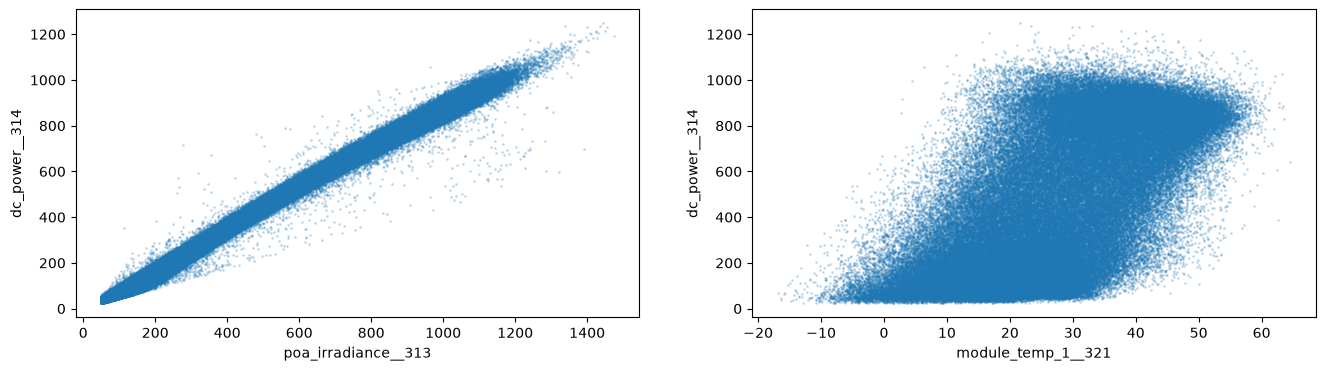

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

# Plot each feature against the target.
for ax, column in zip(axes, FEATURES):
    ax.scatter(df[column], df[TARGET], s=1, alpha=0.2)
    ax.set_xlabel(column)
    ax.set_ylabel(TARGET)

plt.show()

## Creating training and test sets



In [8]:
from sklearn.model_selection import train_test_split

# Chronological split: no shuffling, the test set is the last 20% of the rows.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("Training samples:", len(X_train))
print("Test samples:", len(X_test))

Training samples: 105946
Test samples: 26487


## MinMax normalization

In [9]:
from sklearn.preprocessing import MinMaxScaler

# Fit the scaler on the training set only, then apply the same scaling to the test set.
mms = MinMaxScaler()
X_train_norm = mms.fit_transform(X_train)
X_test_norm = mms.transform(X_test)

print(X_train[:5, :])
print(X_train_norm[:5, :])

[[963.     51.005]
 [257.     44.224]
 [550.     49.53 ]
 [101.     35.646]
 [ 71.     23.91 ]]
[[0.65518988 0.83415079]
 [0.14854676 0.75085707]
 [0.35881083 0.81603278]
 [0.03659729 0.64549009]
 [0.01506854 0.50133213]]


## Training and evaluating the regressors


In [10]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

results = []


def evaluate(name, y_pred, train_seconds):
    """Compare the predicted with the real target values and store one row in results."""
    MAE = mean_absolute_error(y_test, y_pred)
    MSE = mean_squared_error(y_test, y_pred)
    RMSE = np.sqrt(MSE)
    R2 = r2_score(y_test, y_pred)
    results.append([name, MAE, MSE, RMSE, R2, train_seconds])
    print(f"{name}: MAE = {MAE:.1f} W, RMSE = {RMSE:.1f} W, R2 = {R2:.4f}, training time = {train_seconds:.2f} s")

### Linear Regression

In [11]:
from sklearn.linear_model import LinearRegression

# Create a Linear Regression model
LR_Model = LinearRegression()

# Train the model
t0 = time.time()
LR_Model.fit(X_train_norm, y_train)
t1 = time.time()

# Test the model. LR_Pred contains the model's predicted values.
LR_Pred = LR_Model.predict(X_test_norm)

evaluate("Linear Regression", LR_Pred, t1 - t0)
print("Intercept:", LR_Model.intercept_)
print("Coefficients:", LR_Model.coef_)

Linear Regression: MAE = 22.1 W, RMSE = 32.2 W, R2 = 0.9885, training time = 0.01 s
Intercept: 74.3085711444578
Coefficients: [1239.24367402  -66.46681589]


### Decision Tree

In [12]:
from sklearn.tree import DecisionTreeRegressor

# Create a Decision Tree Regression model
# max_depth:        the maximum depth of the tree.
# min_samples_leaf: the minimum number of samples required to be at a leaf node.
DT_Model = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0)

# Train the model
t0 = time.time()
DT_Model.fit(X_train_norm, y_train)
t1 = time.time()

# Test the model. DT_Pred contains the model's predicted values.
DT_Pred = DT_Model.predict(X_test_norm)

evaluate("Decision Tree", DT_Pred, t1 - t0)

Decision Tree: MAE = 19.5 W, RMSE = 29.5 W, R2 = 0.9904, training time = 0.15 s


### Random Forest

In [13]:
from sklearn.ensemble import RandomForestRegressor

# Create a Random Forest comprised of 100 decision trees, with the same limits as the single tree.
RF_Model = RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=50, n_jobs=-1, random_state=0)

# Train the model
t0 = time.time()
RF_Model.fit(X_train_norm, y_train)
t1 = time.time()

# Test the model. RF_Pred contains the model's predicted values.
RF_Pred = RF_Model.predict(X_test_norm)

evaluate("Random Forest", RF_Pred, t1 - t0)

Random Forest: MAE = 19.1 W, RMSE = 29.0 W, R2 = 0.9907, training time = 1.27 s


### Multilayer Perceptron


In [14]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler

# Create an MLP Regression model
mlp = MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=200, batch_size=1024, early_stopping=True, random_state=0)
MLP_Model = TransformedTargetRegressor(regressor=mlp, transformer=StandardScaler())

# Train the model
t0 = time.time()
MLP_Model.fit(X_train_norm, y_train)
t1 = time.time()

# Test the model. MLP_Pred contains the model's predicted values.
MLP_Pred = MLP_Model.predict(X_test_norm)

evaluate("Multilayer Perceptron", MLP_Pred, t1 - t0)

Multilayer Perceptron: MAE = 19.9 W, RMSE = 29.3 W, R2 = 0.9905, training time = 1.79 s


## Results

In [15]:
results_df = pd.DataFrame(results, columns=["Model", "MAE (W)", "MSE", "RMSE (W)", "R2", "Training time (s)"])
results_df.sort_values("RMSE (W)").round(3)

,Model,MAE (W),MSE,RMSE (W),R2,Training time (s)
2,Random Forest,19.145,842.649,29.028,0.991,1.269
3,Multilayer Perceptron,19.871,857.596,29.285,0.991,1.794
1,Decision Tree,19.455,867.713,29.457,0.990,0.153
0,Linear Regression,22.081,1035.134,32.173,0.989,0.006


### Visualizing the results

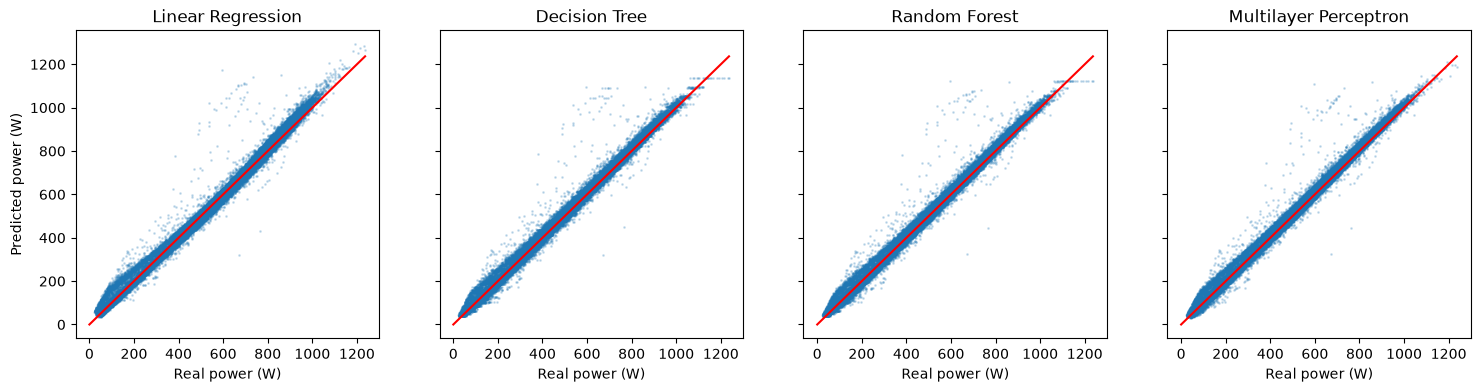

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharex=True, sharey=True)

# Predicted versus real power for every model; the red line marks perfect predictions.
for ax, (name, y_pred) in zip(axes, [("Linear Regression", LR_Pred), ("Decision Tree", DT_Pred),
                                      ("Random Forest", RF_Pred), ("Multilayer Perceptron", MLP_Pred)]):
    ax.scatter(y_test, y_pred, s=1, alpha=0.2)
    ax.plot([0, y_test.max()], [0, y_test.max()], "r")
    ax.set_title(name)
    ax.set_xlabel("Real power (W)")

axes[0].set_ylabel("Predicted power (W)")
plt.show()

## Exercise: a random split

Repeat the Decision Tree with a random split (`random_state=1`). The test error is lower,
but only because the test rows have almost identical neighbours in the training set. Notebook 4 (section 4.3)
measures this effect on the full data.

In [19]:
# Random split (rows shuffled).
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X, y, test_size=0.2, random_state=10)

mms_r = MinMaxScaler()
X_train_r = mms_r.fit_transform(X_train_r)
X_test_r = mms_r.transform(X_test_r)

DT_Model_r = DecisionTreeRegressor(max_depth=12, min_samples_leaf=50, random_state=0)
DT_Model_r.fit(X_train_r, y_train_r)
RMSE_random = np.sqrt(mean_squared_error(y_test_r, DT_Model_r.predict(X_test_r)))
RMSE_chrono = np.sqrt(mean_squared_error(y_test, DT_Pred))

print(f"Decision Tree RMSE, chronological split: {RMSE_chrono:.1f} W")
print(f"Decision Tree RMSE, random split:        {RMSE_random:.1f} W")

Decision Tree RMSE, chronological split: 29.5 W
Decision Tree RMSE, random split:        25.7 W
